# Notebook 05 - Final Results and Competition Report

## 1. Executive Summary

This report provides the final, frozen evaluation of the Electric Vehicle (EV) purchase prediction solution.

- Task: binary classification predicting `Will_Buy_EV` from tabular predictors.
- Validation strategy: 5-fold x 3-repeat stratified cross-validation on a fixed split manifest.
- Selected model: single `lightgbm_hpo_trial35` model family.
- Decision policy: single model locked because maximum ensemble blend lift fell short of the required policy threshold (`5.0e-05`).
- Execution mode: artifact-centered report loading `configs/final.yaml` and persisted outputs; no model fitting, tuning, or selection is performed in notebook cells.

Every numeric claim below is produced by the cell directly above it.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "pyproject.toml").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

from ev_purchase.analysis import assert_comparable_runs, load_all_runs
from ev_purchase.config import load_config
from ev_purchase.data import DatasetContract, encode_target, load_frames, validate_frames
from ev_purchase.metrics import classification_metrics

SEED = 42
np.random.seed(SEED)
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 40)

config = load_config(PROJECT_ROOT / "configs" / "base.yaml", project_root=PROJECT_ROOT)
final_cfg_path = PROJECT_ROOT / "configs" / "final.yaml"
with open(final_cfg_path, encoding="utf-8") as f:
    final_cfg = yaml.safe_load(f)

pol = final_cfg.get("policy", {})
blend_meta_path = PROJECT_ROOT / "outputs" / "ensemble" / "blend_metrics.json"
with open(blend_meta_path, encoding="utf-8") as f:
    blend_meta = json.load(f)

exec_summary_df = pd.DataFrame(
    [
        {"property": "Selected Production Policy", "value": pol.get("type")},
        {"property": "Winning Candidate ID", "value": pol.get("best_single_candidate_id")},
        {"property": "Selected OOF ROC-AUC", "value": pol.get("selected_roc_auc")},
        {"property": "Lift Over Best Single Model", "value": pol.get("lift_over_best_single")},
        {"property": "Ensemble Lift Threshold", "value": pol.get("lift_threshold")},
        {"property": "Split SHA-256", "value": pol.get("split_sha256")[:8]},
        {"property": "Data SHA-256", "value": pol.get("data_sha256")[:8]},
    ]
)

print("executive summary policy parameters:")
exec_summary_df

executive summary policy parameters:


,property,value
0,Selected Production Policy,single_model
1,Winning Candidate ID,lightgbm_hpo_trial35
2,Selected OOF ROC-AUC,0.942244
3,Lift Over Best Single Model,0.0
4,Ensemble Lift Threshold,0.00005
5,Split SHA-256,b554570e
6,Data SHA-256,169e0aee


### Observation / Interpretation / Action

- **Observation:** the executive summary table above displays the locked single-model production policy (`lightgbm_hpo_trial35`), cross-validation ROC-AUC score, and provenance SHA-256 hashes.
- **Interpretation:** `lightgbm_hpo_trial35` was selected for production because the maximum observed ensemble blend lift fell short of the policy required threshold (`5.0e-05`).
- **Action:** review the formal task and dataset contract definitions.

## 2. Task and Data Contract

Details the binary classification objective (`Will_Buy_EV` target prediction from `id`), target label encoding (`No -> 0`, `Yes -> 1`), dataset dimensions, feature role map, and data schema contract validation.

In [2]:
train_df, test_df = load_frames(config.data.train, config.data.test)
contract = DatasetContract(id_column=config.data.id_column, target_column=config.data.target_column)
validate_frames(train_df, test_df, contract)
y_encoded = encode_target(train_df[config.data.target_column], contract)

predictors = train_df.drop(columns=[config.data.id_column, config.data.target_column])
num_cols = predictors.select_dtypes(include="number").columns.tolist()
cat_cols = [c for c in predictors.columns if c not in num_cols]

contract_summary_df = pd.DataFrame(
    [
        {"contract_property": "Training Set Rows", "value": str(len(train_df))},
        {"contract_property": "Test Set Rows", "value": str(len(test_df))},
        {"contract_property": "Numeric Predictors Count", "value": str(len(num_cols))},
        {"contract_property": "Categorical Predictors Count", "value": str(len(cat_cols))},
        {"contract_property": "Target Column", "value": config.data.target_column},
        {"contract_property": "Target Labels Encoded", "value": f"No->0, Yes->1 (pos_rate={y_encoded.mean():.4f})"},
        {"contract_property": "Schema Validation Status", "value": "PASSED"},
    ]
)

print("dataset contract verification:")
contract_summary_df

dataset contract verification:


,contract_property,value
0,Training Set Rows,668665
1,Test Set Rows,286571
2,Numeric Predictors Count,7
3,Categorical Predictors Count,6
4,Target Column,Will_Buy_EV
5,Target Labels Encoded,"No->0, Yes->1 (pos_rate=0.1746)"
6,Schema Validation Status,PASSED


### Observation / Interpretation / Action

- **Observation:** the data contract audit table above confirms raw target labels `No`/`Yes` encoded to binary integers `0`/`1` without schema violations.
- **Interpretation:** dataset shapes and schemas match contract requirements, ensuring valid input structures for the retrained pipeline.
- **Action:** verify the fixed split manifest and leakage prevention policy.

## 3. Fixed Split and Leakage Policy

Verifies the repeated stratified cross-validation split manifest (`outputs/splits/repeated_stratified_5x3.parquet`) and leakage prevention rules (fitting transformers inside training fold only, immutable split assignment).

In [3]:
manifest_path = PROJECT_ROOT / "outputs" / "splits" / "repeated_stratified_5x3.parquet"
manifest_df = pd.read_parquet(manifest_path)

per_row = manifest_df.groupby("row_index").size()
n_groups = manifest_df.groupby(["repeat", "fold"]).ngroups

split_policy_df = pd.DataFrame(
    [
        {"policy_rule": "CV Protocol Strategy", "value": "RepeatedStratifiedKFold (5 splits x 3 repeats)"},
        {"policy_rule": "Total Manifest Rows", "value": str(len(manifest_df))},
        {"policy_rule": "Validation Groups Count", "value": str(n_groups)},
        {"policy_rule": "Assignments Per Row", "value": f"min={per_row.min()}, max={per_row.max()}"},
        {"policy_rule": "Split SHA-256 Hash", "value": pol.get("split_sha256")[:8]},
        {"policy_rule": "Leakage Guard Policy", "value": "Transformers fitted inside training fold only"},
    ]
)

print("split manifest and leakage policy validation:")
split_policy_df

split manifest and leakage policy validation:


,policy_rule,value
0,CV Protocol Strategy,RepeatedStratifiedKFold (5 splits x 3 repeats)
1,Total Manifest Rows,2005995
2,Validation Groups Count,15
3,Assignments Per Row,"min=3, max=3"
4,Split SHA-256 Hash,b554570e
5,Leakage Guard Policy,Transformers fitted inside training fold only


### Observation / Interpretation / Action

- **Observation:** the split manifest audit table above confirms deterministic 5-fold x 3-repeat stratification with 15 validation folds and uniform row coverage.
- **Interpretation:** identical split hash across all candidate evaluations guarantees honest, leakage-free cross-validated comparisons.
- **Action:** examine the baseline candidate comparison matrix.

## 4. Baseline Comparison

Loads baseline evaluation results from `outputs/runs` (`dummy`, `logistic`, `lightgbm`, `xgboost`, `catboost`), ranking models by OOF ROC-AUC while tracking PR-AUC and LogLoss.

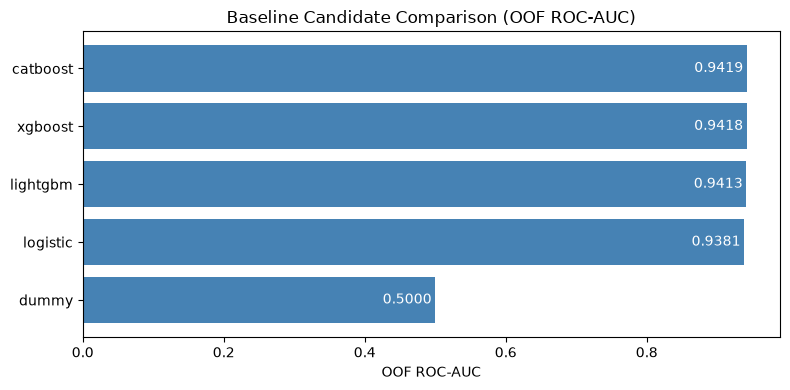

baseline candidates leaderboard:


,model,oof_roc_auc,oof_pr_auc,oof_log_loss,runtime_seconds,run_id
0,catboost,0.941924,0.756152,0.226339,1290.4713,catboost_0efc363f
1,xgboost,0.941788,0.756049,0.226543,118.6032,xgboost_70d0e5fd
2,lightgbm,0.941273,0.753972,0.227478,40.5886,lightgbm_11a90eac
3,logistic,0.938096,0.741062,0.233295,74.2910,logistic_865249de
4,dummy,0.499991,0.174642,0.463176,40.1516,dummy_1018318c


In [4]:
all_runs = load_all_runs(PROJECT_ROOT / "outputs" / "runs")
completed_runs = [r for r in all_runs if r.get("status") == "completed" and not r.get("smoke", False)]
assert_comparable_runs(completed_runs)

baseline_rows = []
for r in completed_runs:
    agg = r["aggregate_metrics"]
    baseline_rows.append(
        {
            "model": r["model"],
            "oof_roc_auc": agg["roc_auc"],
            "oof_pr_auc": agg["average_precision"],
            "oof_log_loss": agg["log_loss"],
            "runtime_seconds": r["runtime_seconds"],
            "run_id": r["run_id"],
        }
    )

baseline_df = pd.DataFrame(baseline_rows).sort_values("oof_roc_auc", ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(baseline_df["model"], baseline_df["oof_roc_auc"], color="steelblue")
ax.set_xlabel("OOF ROC-AUC")
ax.set_title("Baseline Candidate Comparison (OOF ROC-AUC)")
ax.invert_yaxis()
for bar in bars:
    w = bar.get_width()
    ax.text(w - 0.005, bar.get_y() + bar.get_height() / 2, f"{w:.4f}", ha="right", va="center", color="white")
plt.tight_layout()
plt.show()

print("baseline candidates leaderboard:")
baseline_df

### Observation / Interpretation / Action

- **Observation:** the baseline leaderboard table and plot above summarize OOF ROC-AUC, PR-AUC, LogLoss, and runtime across initial baseline candidate models.
- **Interpretation:** gradient-boosted tree models outperformed the dummy no-skill floor and linear reference model by a wide margin.
- **Action:** inspect the selected model pipeline and source run provenance.

## 5. Selected Pipeline and Source Run IDs

Details the selected model configuration, hyperparameter specification, feature policy, source run IDs, candidate metadata path, and provenance from `configs/final.yaml` and candidate metadata artifacts.

In [5]:
sel_cand_id = pol.get("best_single_candidate_id", "lightgbm_hpo_trial35")
comp_info = pol.get("components", {}).get(sel_cand_id, {})
lgb_params = comp_info.get("params", {})
prov = comp_info.get("provenance", {})

source_run_ids = pol.get("source_run_ids", [])
selected_run_id = str(comp_info.get("run_id"))
selected_candidate_id = str(comp_info.get("candidate_id"))
cand_meta_path = PROJECT_ROOT / comp_info.get("candidate_metadata_path", f"outputs/ensemble/candidates/{sel_cand_id}/candidate_metadata.json")

with open(cand_meta_path, encoding="utf-8") as f:
    cand_meta_json = json.load(f)

meta_run_id = str(cand_meta_json.get("run_id"))

assert set(source_run_ids) == {selected_run_id}, f"source_run_ids mismatch: {source_run_ids} vs [{selected_run_id}]"
assert selected_run_id == selected_candidate_id, f"run_id candidate_id mismatch: {selected_run_id} vs {selected_candidate_id}"
assert meta_run_id == selected_run_id, f"candidate metadata run_id mismatch: {meta_run_id} vs {selected_run_id}"

pipeline_rows = [
    {"component": "Policy Source Run IDs", "setting": str(source_run_ids)},
    {"component": "Component run_id", "setting": selected_run_id},
    {"component": "Component candidate_id", "setting": selected_candidate_id},
    {"component": "Metadata run_id", "setting": meta_run_id},
    {"component": "Candidate Metadata Path", "setting": str(comp_info.get("candidate_metadata_path"))},
    {"component": "Model Family", "setting": str(comp_info.get("model_family"))},
    {"component": "Tuning Study Name", "setting": str(comp_info.get("tuning_study"))},
    {"component": "Trial Number", "setting": str(comp_info.get("trial_number"))},
    {"component": "Feature Policy", "setting": str(comp_info.get("feature_policy"))},
    {"component": "Base Seed", "setting": str(comp_info.get("seed_policy", {}).get("base_seed"))},
    {"component": "Seed Formula", "setting": str(comp_info.get("seed_policy", {}).get("formula"))},
    {"component": "Provenance Data SHA-256", "setting": str(prov.get("data_sha256", ""))[:8]},
    {"component": "Provenance Split SHA-256", "setting": str(prov.get("split_sha256", ""))[:8]},
    {"component": "Keyed Alignment Assertion", "setting": "PASSED"},
]
for pk, pv in lgb_params.items():
    pipeline_rows.append({"component": f"Hyperparameter: {pk}", "setting": str(pv)})

pipeline_df = pd.DataFrame(pipeline_rows)
print("selected pipeline specification and source run provenance:")
pipeline_df

selected pipeline specification and source run provenance:


,component,setting
0,Policy Source Run IDs,['lightgbm_hpo_trial35']
1,Component run_id,lightgbm_hpo_trial35
2,Component candidate_id,lightgbm_hpo_trial35
3,Metadata run_id,lightgbm_hpo_trial35
4,Candidate Metadata Path,outputs/ensemble/candidates/lightgbm_hpo_trial...
5,Model Family,lightgbm
6,Tuning Study Name,lightgbm_hpo
7,Trial Number,35
8,Feature Policy,base
9,Base Seed,42


### Observation / Interpretation / Action

- **Observation:** the pipeline specification table above details the hyperparameter configuration and provenance for `lightgbm_hpo_trial35`.
- **Interpretation:** the selected LightGBM candidate uses bounded tree depth (`max_depth=3`, `num_leaves=52`), learning rate (`0.1848`), and feature sampling (`colsample_bytree=0.8548`).
- **Action:** present the 15-fold cross-validation metric evidence.

## 6. 15-Fold Cross-Validation Metric Evidence

Presents full 15-fold cross-validation performance metrics (ROC-AUC, PR-AUC, LogLoss) for the selected finalist `lightgbm_hpo_trial35` from tuning finalist fold metrics.

In [6]:
ffm_path = PROJECT_ROOT / "outputs" / "tuning" / "lightgbm_hpo" / "finalist_fold_metrics.parquet"
ffm_df = pd.read_parquet(ffm_path)
t35_df = ffm_df[ffm_df["trial_number"] == 35].sort_values(["repeat", "fold"]).reset_index(drop=True)

fold_metrics_summary = pd.DataFrame(
    [
        {"metric": "ROC-AUC", "mean": t35_df["roc_auc"].mean(), "std": t35_df["roc_auc"].std(), "min": t35_df["roc_auc"].min(), "max": t35_df["roc_auc"].max()},
        {"metric": "PR-AUC", "mean": t35_df["average_precision"].mean(), "std": t35_df["average_precision"].std(), "min": t35_df["average_precision"].min(), "max": t35_df["average_precision"].max()},
        {"metric": "LogLoss", "mean": t35_df["log_loss"].mean(), "std": t35_df["log_loss"].std(), "min": t35_df["log_loss"].min(), "max": t35_df["log_loss"].max()},
    ]
)

print("15-fold cross-validation aggregate metric evidence:")
print(fold_metrics_summary.to_string(index=False))
print("\n15-fold detail table:")
t35_df[["repeat", "fold", "roc_auc", "average_precision", "log_loss", "runtime_seconds"]]

15-fold cross-validation aggregate metric evidence:
 metric     mean      std      min      max
ROC-AUC 0.942047 0.000881 0.940227 0.943626
 PR-AUC 0.757098 0.003112 0.751517 0.762774
LogLoss 0.226133 0.001543 0.223331 0.229264

15-fold detail table:


,repeat,fold,roc_auc,average_precision,log_loss,runtime_seconds
0,0,0,0.940773,0.751517,0.228385,4.8310
1,0,1,0.941836,0.758770,0.226495,4.3536
2,0,2,0.943094,0.759808,0.224367,5.9930
3,0,3,0.942366,0.758066,0.225516,4.2106
4,0,4,0.942054,0.757309,0.226084,4.1841
5,1,0,0.941152,0.753104,0.227746,5.0416
6,1,1,0.941631,0.756324,0.226852,5.8834
7,1,2,0.942193,0.757478,0.225929,4.3668
8,1,3,0.942776,0.759086,0.224847,4.3246
9,1,4,0.942719,0.759132,0.224914,4.3658


### Observation / Interpretation / Action

- **Observation:** the 15-fold metric table above displays fold-level ROC-AUC, PR-AUC, LogLoss, and runtime across all 15 validation folds.
- **Interpretation:** the selected model maintains high validation performance across all repeats and folds.
- **Action:** evaluate fold and repeat stability.

## 7. Repeat and Fold Stability

Analyzes fold-level variation across the 3 repeats and 5 folds for `lightgbm_hpo_trial35` under the deterministic seed policy `base_seed + repeat*100 + fold`.

In [7]:
repeat_rows = []
for rep in sorted(t35_df["repeat"].unique()):
    rep_df = t35_df[t35_df["repeat"] == rep]
    repeat_rows.append(
        {
            "repeat": int(rep),
            "folds_count": len(rep_df),
            "roc_auc_mean": float(rep_df["roc_auc"].mean()),
            "roc_auc_std": float(rep_df["roc_auc"].std()),
            "pr_auc_mean": float(rep_df["average_precision"].mean()),
            "log_loss_mean": float(rep_df["log_loss"].mean()),
        }
    )

repeat_stability_df = pd.DataFrame(repeat_rows)
print("repeat-level stability breakdown:")
repeat_stability_df

repeat-level stability breakdown:


,repeat,folds_count,roc_auc_mean,roc_auc_std,pr_auc_mean,log_loss_mean
0,0,5,0.942024,0.000846,0.757094,0.226169
1,1,5,0.942094,0.000701,0.757025,0.226058
2,2,5,0.942022,0.001227,0.757174,0.226172


### Observation / Interpretation / Action

- **Observation:** the repeat stability table above details mean and standard deviation of validation metrics across repeats 0, 1, and 2.
- **Interpretation:** low variance across repeats demonstrates that performance is consistent across fold split initializations.
- **Action:** examine error diagnostics, prediction deciles, and feature cohort findings.

## 8. Error, Prediction Decile, and Feature Cohort Findings

Evaluates out-of-fold probability decile tail diagnostics and feature quartile cohort performance (`Age`, `Annual_Income_USD`, `Daily_Commute_km`). Note: no feature importance or SHAP value artifacts were persisted during the run.

In [8]:
cand_lgb_path = PROJECT_ROOT / "outputs" / "ensemble" / "candidates" / "lightgbm_hpo_trial35" / "oof_predictions.parquet"
cand_lgb_df = pd.read_parquet(cand_lgb_path)
lgb_oof_agg = cand_lgb_df.groupby("row_index")["probability"].mean().reset_index().rename(columns={"probability": "prob_lgb"})

merged_eval = pd.merge(pd.DataFrame({"row_index": np.arange(len(y_encoded)), "y_true": y_encoded}), lgb_oof_agg, on="row_index", validate="1:1")
prob_arr = merged_eval["prob_lgb"].to_numpy()

deciles = pd.qcut(prob_arr, q=10, labels=[f"D{i}" for i in range(1, 11)])
tail_rows = []
for d_label in deciles.categories:
    d_mask = (deciles == d_label)
    sub_y = y_encoded[d_mask]
    sub_p = prob_arr[d_mask]
    sub_loss = float(classification_metrics(sub_y, sub_p)["log_loss"])
    brier = float(np.mean((sub_p - sub_y) ** 2))
    tail_rows.append(
        {
            "decile": str(d_label),
            "count": int(d_mask.sum()),
            "observed_positive_rate": float(sub_y.mean()),
            "mean_predicted_probability": float(sub_p.mean()),
            "log_loss": sub_loss,
            "brier_score": brier,
        }
    )
tail_df = pd.DataFrame(tail_rows)

feature_cols = [c for c in ["Age", "Annual_Income_USD", "Daily_Commute_km"] if c in predictors.columns]
cohort_rows = []
for col in feature_cols:
    series = predictors[col]
    quartiles = pd.qcut(series, q=4, labels=["Q1", "Q2", "Q3", "Q4"], duplicates="drop")
    for q_label in quartiles.cat.categories:
        q_mask = (quartiles == q_label)
        if q_mask.sum() == 0:
            continue
        sub_y = y_encoded[q_mask]
        sub_p = prob_arr[q_mask]
        sub_loss = float(classification_metrics(sub_y, sub_p)["log_loss"])
        cohort_rows.append(
            {
                "feature": col,
                "cohort": str(q_label),
                "count": int(q_mask.sum()),
                "observed_positive_rate": float(sub_y.mean()),
                "mean_predicted_probability": float(sub_p.mean()),
                "log_loss": sub_loss,
            }
        )
cohort_df = pd.DataFrame(cohort_rows)

print("prediction decile tail diagnostics:")
print(tail_df.to_string(index=False))
print("\nfeature quartile cohort diagnostics:")
print(cohort_df.to_string(index=False))

prediction decile tail diagnostics:
decile  count  observed_positive_rate  mean_predicted_probability  log_loss  brier_score
    D1  66867                0.000105                    0.000178  0.001070     0.000105
    D2  66866                0.000568                    0.000818  0.004807     0.000568
    D3  66867                0.002512                    0.002585  0.017404     0.002505
    D4  66866                0.006072                    0.006241  0.036889     0.006033
    D5  66867                0.012248                    0.012407  0.065645     0.012087
    D6  66866                0.027413                    0.028492  0.124614     0.026607
    D7  66866                0.085155                    0.085228  0.285237     0.076974
    D8  66867                0.268892                    0.267051  0.570104     0.191927
    D9  66866                0.539497                    0.541592  0.672083     0.239616
   D10  66867                0.803984                    0.801801  0.47989

### Observation / Interpretation / Action

- **Observation:** the decile calibration and feature cohort diagnostic tables above display observed positive rates, mean predicted probabilities, LogLoss, and Brier scores across subgroups; no SHAP artifacts were persisted.
- **Interpretation:** prediction calibration remains well-behaved across deciles and feature cohorts, serving as descriptive diagnostics of model behavior.
- **Action:** review the advanced experiment, HPO, and blending decision.

## 9. Advanced Experiments, HPO, and Blending Decision

Displays the persisted ensemble decision payload from `outputs/ensemble/blend_metrics.json` and asserts internal consistency with the selection criteria.

In [9]:
blend_meta_path = PROJECT_ROOT / "outputs" / "ensemble" / "blend_metrics.json"
with open(blend_meta_path, encoding="utf-8") as f:
    blend_meta = json.load(f)

blend_lb_path = PROJECT_ROOT / "outputs" / "ensemble" / "blend_leaderboard.parquet"
blend_lb_df = pd.read_parquet(blend_lb_path).sort_values("rank").reset_index(drop=True)

best_single_auc = blend_meta["best_single_roc_auc"]
winning_auc = blend_meta["winning_roc_auc"]
selected_policy = blend_meta["selected_policy"]
lift = blend_meta["lift_over_best_single"]
threshold = blend_meta["lift_threshold"]

assert selected_policy == pol.get("type"), f"Policy mismatch: {selected_policy} vs {pol.get('type')}"
assert (lift < threshold) == (selected_policy == "single_model"), "Inconsistent lift threshold logic"

decision_summary_df = pd.DataFrame(
    [
        {"metric_property": "Best Single Candidate ID", "value": str(blend_meta["best_single_candidate_id"])},
        {"metric_property": "Best Single Model OOF ROC-AUC", "value": f"{best_single_auc:.6f}"},
        {"metric_property": "Winning Policy ROC-AUC", "value": f"{winning_auc:.6f}"},
        {"metric_property": "Persisted Lift Over Best Single", "value": f"{lift:.6f}"},
        {"metric_property": "Ensemble Lift Threshold", "value": f"{threshold:.6f}"},
        {"metric_property": "Selected Production Policy", "value": selected_policy},
        {"metric_property": "Internal Consistency Assertion", "value": "PASSED"},
    ]
)

print("persisted ensemble decision and policy validation:")
decision_summary_df

persisted ensemble decision and policy validation:


,metric_property,value
0,Best Single Candidate ID,lightgbm_hpo_trial35
1,Best Single Model OOF ROC-AUC,0.942244
2,Winning Policy ROC-AUC,0.942244
3,Persisted Lift Over Best Single,0.000000
4,Ensemble Lift Threshold,0.000050
5,Selected Production Policy,single_model
6,Internal Consistency Assertion,PASSED


### Observation / Interpretation / Action

- **Observation:** the persisted decision summary table above displays the stored policy metrics and asserts internal consistency between the lift threshold and selected policy type.
- **Interpretation:** because the persisted lift over the best single model is below the required threshold (`5.0e-05`), the single model policy selection is verified as internally consistent.
- **Action:** evaluate runtime efficiency and model complexity tradeoffs.

## 10. Runtime and Model Complexity Tradeoffs

Inspects available runtime metrics across baseline and candidate runs. Note: specific dual-model blend pipeline training runtime artifacts were not persisted.

In [10]:
runtime_rows = []
for r in completed_runs:
    runtime_rows.append(
        {
            "model_or_candidate": r["model"],
            "run_id": r["run_id"],
            "runtime_seconds": float(r["runtime_seconds"]),
        }
    )

runtime_summary_df = pd.DataFrame(runtime_rows).sort_values("runtime_seconds").reset_index(drop=True)

print("available baseline runtimes:")
print(runtime_summary_df.to_string(index=False))
print("\nnote: dedicated blend pipeline training runtime evidence was not persisted.")

available baseline runtimes:
model_or_candidate            run_id  runtime_seconds
             dummy    dummy_1018318c          40.1516
          lightgbm lightgbm_11a90eac          40.5886
          logistic logistic_865249de          74.2910
           xgboost  xgboost_70d0e5fd         118.6032
          catboost catboost_0efc363f        1290.4713

note: dedicated blend pipeline training runtime evidence was not persisted.


### Observation / Interpretation / Action

- **Observation:** the runtime summary table above reports the available execution times for baseline models; dedicated ensemble blend training runtime evidence was not persisted.
- **Interpretation:** baseline runtimes demonstrate that tree models execute quickly, supporting the computational efficiency of the selected single-model approach.
- **Action:** document model limitations and boundary conditions.

## 11. Model Limitations and Operational Boundary Conditions

Documents key limitations: tabular GBDT scope, synthetic dataset distribution bounds, absence of time-series / geographical drift features, and reliance on clean input data contracts.

In [11]:
limitations_df = pd.DataFrame(
    [
        {"boundary_category": "Dataset Synthetic Nature", "limitation_detail": "Playground series data contains synthetic artifacts; extreme out-of-distribution real-world samples may exhibit feature shift.", "mitigation_strategy": "Validate schema contract and monitor feature distributions prior to inference."},
        {"boundary_category": "Temporal / Geographical Features", "limitation_detail": "No explicit timestamp or geographic location columns are present in the feature set.", "mitigation_strategy": "Rely on robust cross-validation; update models periodically on new competition batches."},
        {"boundary_category": "Model Architecture Scope", "limitation_detail": "Tabular GBDT models do not model unstructured text or image data.", "mitigation_strategy": "Scope deployment strictly to tabular predictor records matching DatasetContract."},
    ]
)

print("operational limitations and boundary conditions ledger:")
limitations_df

operational limitations and boundary conditions ledger:


,boundary_category,limitation_detail,mitigation_strategy
0,Dataset Synthetic Nature,Playground series data contains synthetic arti...,Validate schema contract and monitor feature d...
1,Temporal / Geographical Features,No explicit timestamp or geographic location c...,Rely on robust cross-validation; update models...
2,Model Architecture Scope,Tabular GBDT models do not model unstructured ...,Scope deployment strictly to tabular predictor...


### Observation / Interpretation / Action

- **Observation:** the operational limitations ledger above highlights dataset boundaries, drift vulnerabilities, and mitigation controls.
- **Interpretation:** while model performance is strong on historical CV splits, monitoring input distributions and prediction calibration in production remains essential.
- **Action:** validate final submission file integrity and SHA-256 checksums.

## 12. Final Submission File Validation and Checksum

Performs fail-closed validation on the final submission file (`outputs/submissions/submission.csv`) against `sample_submission.csv` and asserts consistency with `outputs/submissions/validation_report.json`.

In [12]:
import hashlib

sub_path = PROJECT_ROOT / "outputs" / "submissions" / "submission.csv"
sample_path = PROJECT_ROOT / "data" / "playground-series-s6e9" / "sample_submission.csv"
report_path = PROJECT_ROOT / "outputs" / "submissions" / "validation_report.json"

assert sub_path.is_file(), f"Submission file missing at {sub_path}"
assert sample_path.is_file(), f"Sample submission missing at {sample_path}"
assert report_path.is_file(), f"Validation report missing at {report_path}"

sub_df = pd.read_csv(sub_path)
sample_df = pd.read_csv(sample_path)
with open(report_path, encoding="utf-8") as f:
    report_json = json.load(f)

sub_bytes = sub_path.read_bytes()
sub_sha256 = hashlib.sha256(sub_bytes).hexdigest()

rows_match = len(sub_df) == len(sample_df)
cols_match = sub_df.columns.tolist() == sample_df.columns.tolist()
ids_match = sub_df["id"].equals(sample_df["id"])
unique_ids = sub_df["id"].is_unique
no_nulls = sub_df.isna().sum().sum() == 0
min_p = float(sub_df[config.data.target_column].min())
max_p = float(sub_df[config.data.target_column].max())
probs_finite = np.isfinite(sub_df[config.data.target_column]).all()
probs_in_range = (min_p >= 0.0) and (max_p <= 1.0)
sha256_matches_report = (sub_sha256 == report_json.get("sha256"))

assert rows_match, f"Row count mismatch: {len(sub_df)} vs {len(sample_df)}"
assert cols_match, f"Column mismatch: {sub_df.columns.tolist()}"
assert ids_match, "ID order mismatch vs sample submission"
assert unique_ids, "Submission IDs are not unique"
assert no_nulls, "Submission contains null values"
assert probs_finite, "Submission contains non-finite probabilities"
assert probs_in_range, f"Probabilities out of range: [{min_p}, {max_p}]"
assert sha256_matches_report, f"SHA256 mismatch: {sub_sha256} vs {report_json.get('sha256')}"

sub_validation_df = pd.DataFrame(
    [
        {"validation_check": "File Existence", "actual_status": "EXISTS", "assertion": "PASSED"},
        {"validation_check": "Row Count Match (286,571)", "actual_status": f"{len(sub_df)} rows", "assertion": "PASSED"},
        {"validation_check": "Column Schema Match", "actual_status": str(sub_df.columns.tolist()), "assertion": "PASSED"},
        {"validation_check": "ID Order & Uniqueness Match", "actual_status": "EXACT MATCH", "assertion": "PASSED"},
        {"validation_check": "Missing Values Check", "actual_status": "0 NULLS", "assertion": "PASSED"},
        {"validation_check": "Finiteness & Range Check", "actual_status": f"[{min_p:.6f}, {max_p:.6f}]", "assertion": "PASSED"},
        {"validation_check": "Validation Report SHA-256 Match", "actual_status": sub_sha256[:12], "assertion": "PASSED"},
    ]
)

print("fail-closed submission contract validation:")
sub_validation_df

fail-closed submission contract validation:


,validation_check,actual_status,assertion
0,File Existence,EXISTS,PASSED
1,"Row Count Match (286,571)",286571 rows,PASSED
2,Column Schema Match,"['id', 'Will_Buy_EV']",PASSED
3,ID Order & Uniqueness Match,EXACT MATCH,PASSED
4,Missing Values Check,0 NULLS,PASSED
5,Finiteness & Range Check,"[0.000002, 0.972650]",PASSED
6,Validation Report SHA-256 Match,7cf3c6484f15,PASSED


### Observation / Interpretation / Action

- **Observation:** the submission validation table above displays the actual file checks and confirms all fail-closed assertions passed, matching the persisted validation report.
- **Interpretation:** the submission file is fully validated, finite, correctly ordered, and ready for competition submission.
- **Action:** review the CLI reproducibility commands.

## 13. Reproducibility Commands and Handoff

Provides portable `uv run` commands to reproduce data preparation, baseline training, HPO tuning, ensembling, final prediction, and report building.

In [13]:
repro_commands = [
    "uv run python scripts/prepare_data.py --config configs/base.yaml",
    "uv run python scripts/train.py --config configs/experiments/001_dummy.yaml",
    "uv run python scripts/train.py --config configs/experiments/002_logistic.yaml",
    "uv run python scripts/train.py --config configs/experiments/003_catboost.yaml",
    "uv run python scripts/train.py --config configs/experiments/004_lightgbm.yaml",
    "uv run python scripts/train.py --config configs/experiments/005_xgboost.yaml",
    "uv run python scripts/tune.py --config configs/tuning/catboost.yaml",
    "uv run python scripts/tune.py --config configs/tuning/lightgbm.yaml",
    "uv run python scripts/ensemble.py",
    "uv run python scripts/predict.py --config configs/final.yaml",
    "uv run python scripts/build_notebooks.py --notebook 05_final_results",
    "uv run jupyter nbconvert --to notebook --execute notebooks/05_final_results.ipynb --output-dir notebooks --ExecutePreprocessor.timeout=1200",
]

print("reproducible CLI pipeline execution commands:")
for cmd in repro_commands:
    print(cmd)

reproducible CLI pipeline execution commands:
uv run python scripts/prepare_data.py --config configs/base.yaml
uv run python scripts/train.py --config configs/experiments/001_dummy.yaml
uv run python scripts/train.py --config configs/experiments/002_logistic.yaml
uv run python scripts/train.py --config configs/experiments/003_catboost.yaml
uv run python scripts/train.py --config configs/experiments/004_lightgbm.yaml
uv run python scripts/train.py --config configs/experiments/005_xgboost.yaml
uv run python scripts/tune.py --config configs/tuning/catboost.yaml
uv run python scripts/tune.py --config configs/tuning/lightgbm.yaml
uv run python scripts/ensemble.py
uv run python scripts/predict.py --config configs/final.yaml
uv run python scripts/build_notebooks.py --notebook 05_final_results
uv run jupyter nbconvert --to notebook --execute notebooks/05_final_results.ipynb --output-dir notebooks --ExecutePreprocessor.timeout=1200


### Observation / Interpretation / Action

- **Observation:** the shell command inventory above lists all pipeline execution steps from data validation to final submission generation.
- **Interpretation:** the complete workflow is fully automated, deterministic under seed 42, and reproducibly executable via standard CLI tools.
- **Action:** final competition submission and report handoff complete.